In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\rushi\.cache\kagglehub\datasets\jessemostipak\hotel-booking-demand\versions\1


Hotels lose revenue when bookings are canceled, especially late cancellations that leave rooms empty.

**Goal:** predict whether a booking will be canceled (`is_canceled`, 1 = canceled) using only information
known at booking time, so a hotel can overbook strategically, require deposits, or contact at-risk guests.

In [3]:
import pandas as pd
import numpy as np
df = pd.read_csv(f'{path}/hotel_bookings.csv')

In [4]:
df = df.drop_duplicates()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import calendar

In [29]:
raw = pd.read_csv(f'{path}/hotel_bookings.csv')
eda = raw.drop_duplicates().copy()
eda['canceled'] = eda['is_canceled'].map({0: 'Not canceled', 1: 'Canceled'})
print(f"Raw rows: {len(raw):,} | after removing duplicates: {len(eda):,} ({len(raw) - len(eda):,} duplicates)")

Raw rows: 119,390 | after removing duplicates: 87,396 (31,994 duplicates)


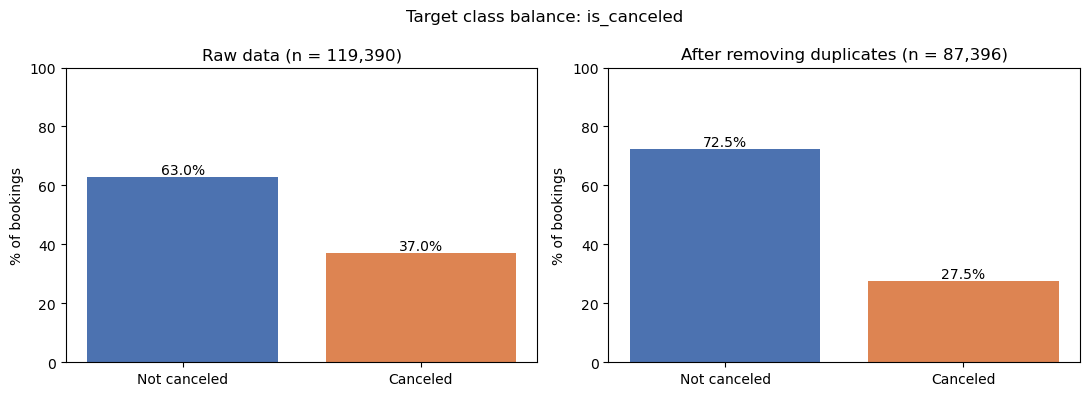

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, title in [(axes[0], raw, 'Raw data'), (axes[1], eda, 'After removing duplicates')]:
    rates = data['is_canceled'].value_counts(normalize=True).sort_index() * 100
    bars = ax.bar(['Not canceled', 'Canceled'], rates.values, color=['#4C72B0', '#DD8452'])
    ax.bar_label(bars, fmt='%.1f%%')
    ax.set_title(f'{title} (n = {len(data):,})')
    ax.set_ylabel('% of bookings')
    ax.set_ylim(0, 100)
plt.suptitle('Target class balance: is_canceled')
plt.tight_layout()
plt.show()

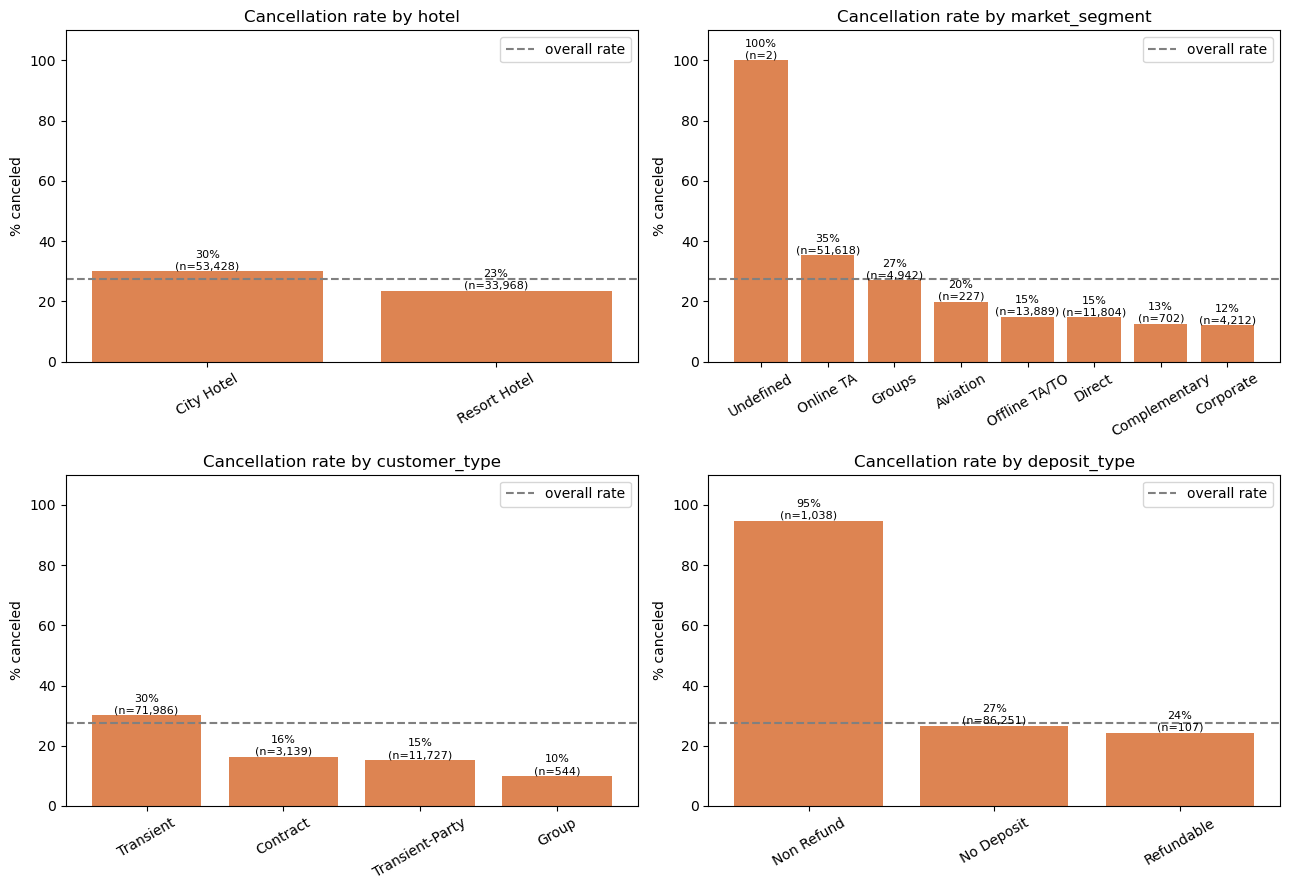

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, ['hotel', 'market_segment', 'customer_type', 'deposit_type']):
    stats = eda.groupby(col)['is_canceled'].agg(['mean', 'size']).sort_values('mean', ascending=False)
    bars = ax.bar(stats.index.astype(str), stats['mean'] * 100, color='#DD8452')
    ax.bar_label(bars, labels=[f"{m:.0%}\n(n={n:,})" for m, n in zip(stats['mean'], stats['size'])], fontsize=8)
    ax.axhline(eda['is_canceled'].mean() * 100, ls='--', c='gray', label='overall rate')
    ax.set_title(f'Cancellation rate by {col}')
    ax.set_ylabel('% canceled')
    ax.set_ylim(0, 110)
    ax.tick_params(axis='x', rotation=30)
    ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

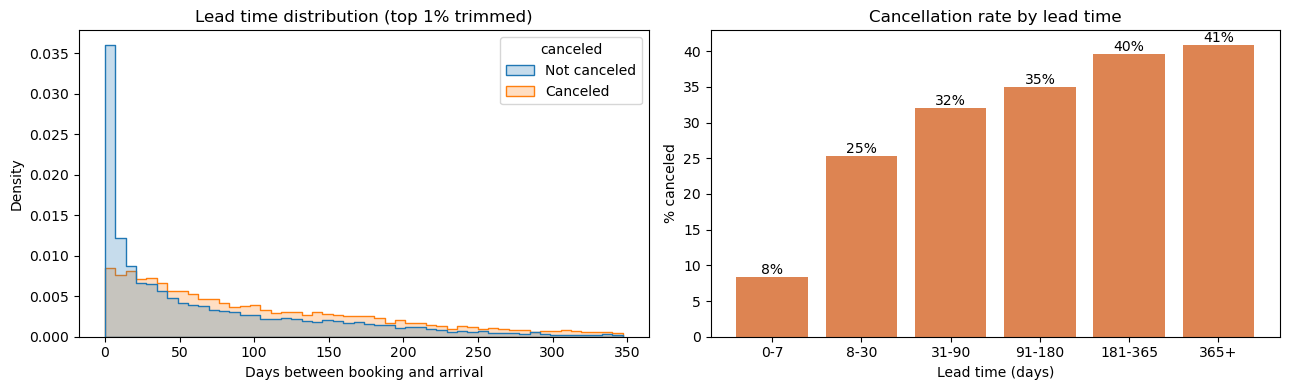

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cap = eda['lead_time'].quantile(0.99)
sns.histplot(data=eda[eda['lead_time'] <= cap], x='lead_time', hue='canceled', bins=50,
             stat='density', common_norm=False, element='step', ax=axes[0])
axes[0].set_title('Lead time distribution (top 1% trimmed)')
axes[0].set_xlabel('Days between booking and arrival')

eda['lead_bucket'] = pd.cut(eda['lead_time'], bins=[-1, 7, 30, 90, 180, 365, 1000],
                            labels=['0-7', '8-30', '31-90', '91-180', '181-365', '365+'])
rate = eda.groupby('lead_bucket', observed=True)['is_canceled'].mean() * 100
bars = axes[1].bar(rate.index.astype(str), rate.values, color='#DD8452')
axes[1].bar_label(bars, fmt='%.0f%%')
axes[1].set_title('Cancellation rate by lead time')
axes[1].set_xlabel('Lead time (days)')
axes[1].set_ylabel('% canceled')
plt.tight_layout()
plt.show()

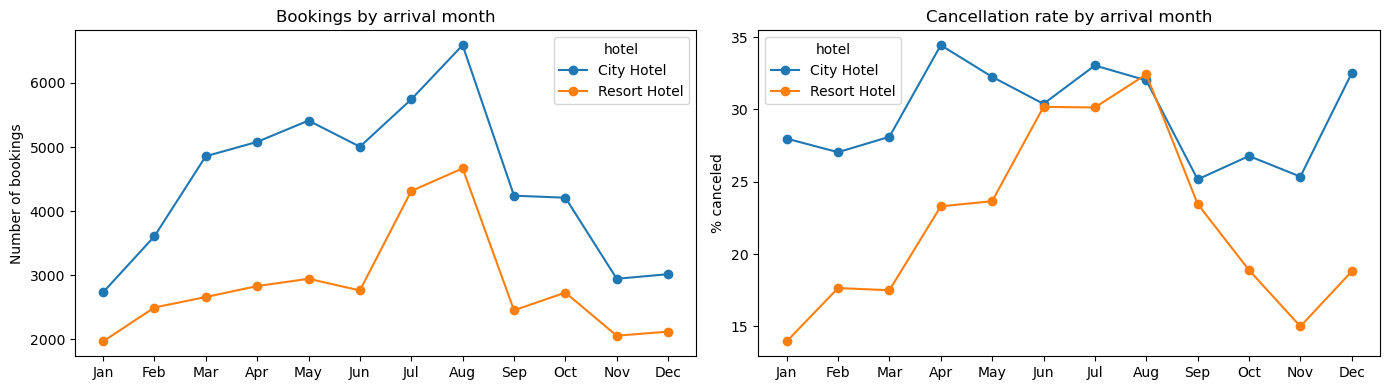

In [33]:
month_order = list(calendar.month_name)[1:]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
counts = eda.groupby(['arrival_date_month', 'hotel']).size().unstack().reindex(month_order)
counts.plot(marker='o', ax=axes[0])
axes[0].set_title('Bookings by arrival month')
axes[0].set_ylabel('Number of bookings')
rates = (eda.groupby(['arrival_date_month', 'hotel'])['is_canceled'].mean().unstack().reindex(month_order) * 100)
rates.plot(marker='o', ax=axes[1])
axes[1].set_title('Cancellation rate by arrival month')
axes[1].set_ylabel('% canceled')
for ax in axes:
    ax.set_xticks(range(12))
    ax.set_xticklabels([m[:3] for m in month_order])
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

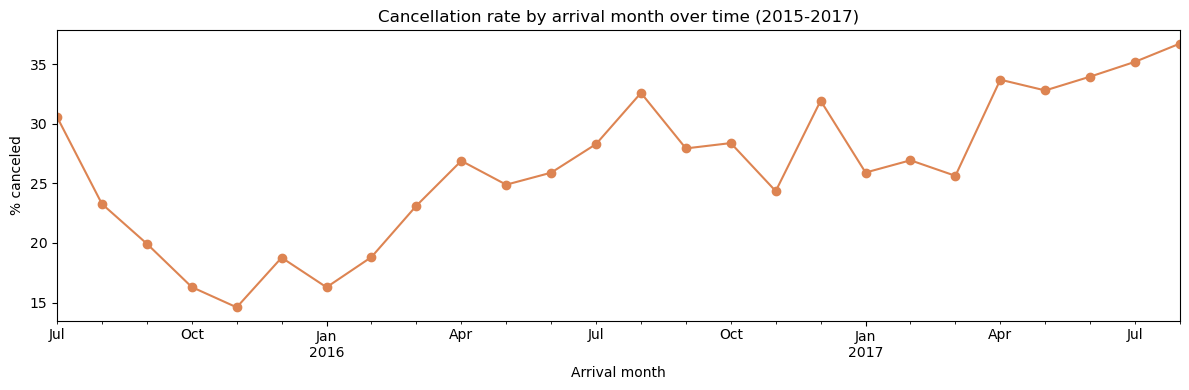

In [34]:
eda['arrival_ym'] = pd.to_datetime(eda['arrival_date_year'].astype(str) + '-' +
                                   eda['arrival_date_month'].map({m: i for i, m in enumerate(month_order, 1)}).astype(str) + '-01')
monthly = eda.groupby('arrival_ym')['is_canceled'].mean() * 100
ax = monthly.plot(marker='o', figsize=(12, 4), color='#DD8452')
ax.set_title('Cancellation rate by arrival month over time (2015-2017)')
ax.set_ylabel('% canceled')
ax.set_xlabel('Arrival month')
plt.tight_layout()
plt.show()

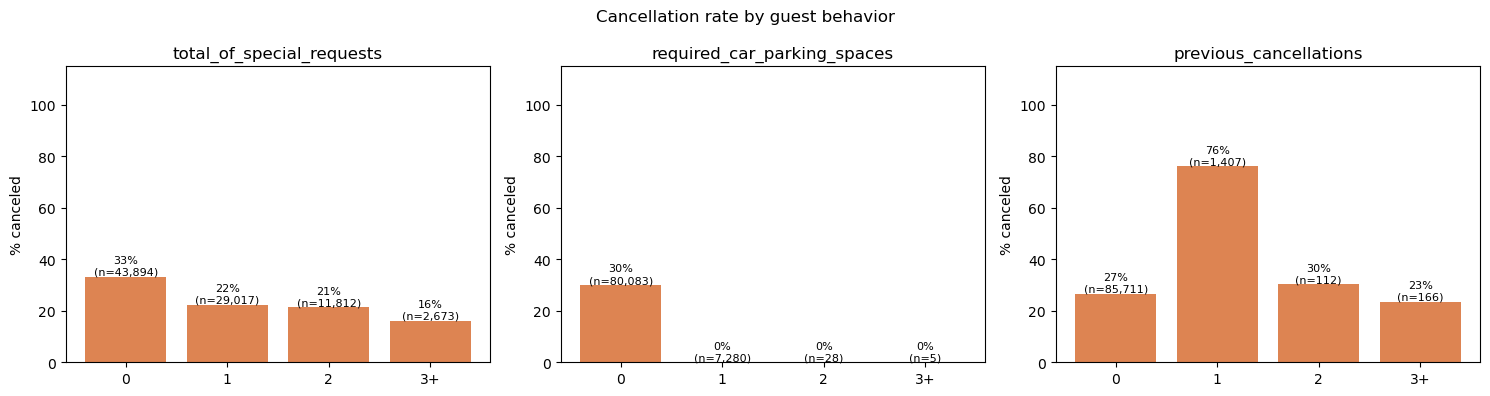

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['total_of_special_requests', 'required_car_parking_spaces', 'previous_cancellations']):
    data = eda.copy()
    data[col] = data[col].clip(upper=3)   # group the long tail as "3+"
    stats = data.groupby(col)['is_canceled'].agg(['mean', 'size'])
    labels = [str(v) if v < 3 else '3+' for v in stats.index]
    bars = ax.bar(labels, stats['mean'] * 100, color='#DD8452')
    ax.bar_label(bars, labels=[f"{m:.0%}\n(n={n:,})" for m, n in zip(stats['mean'], stats['size'])], fontsize=8)
    ax.set_title(col)
    ax.set_ylabel('% canceled')
    ax.set_ylim(0, 115)
plt.suptitle('Cancellation rate by guest behavior')
plt.tight_layout()
plt.show()

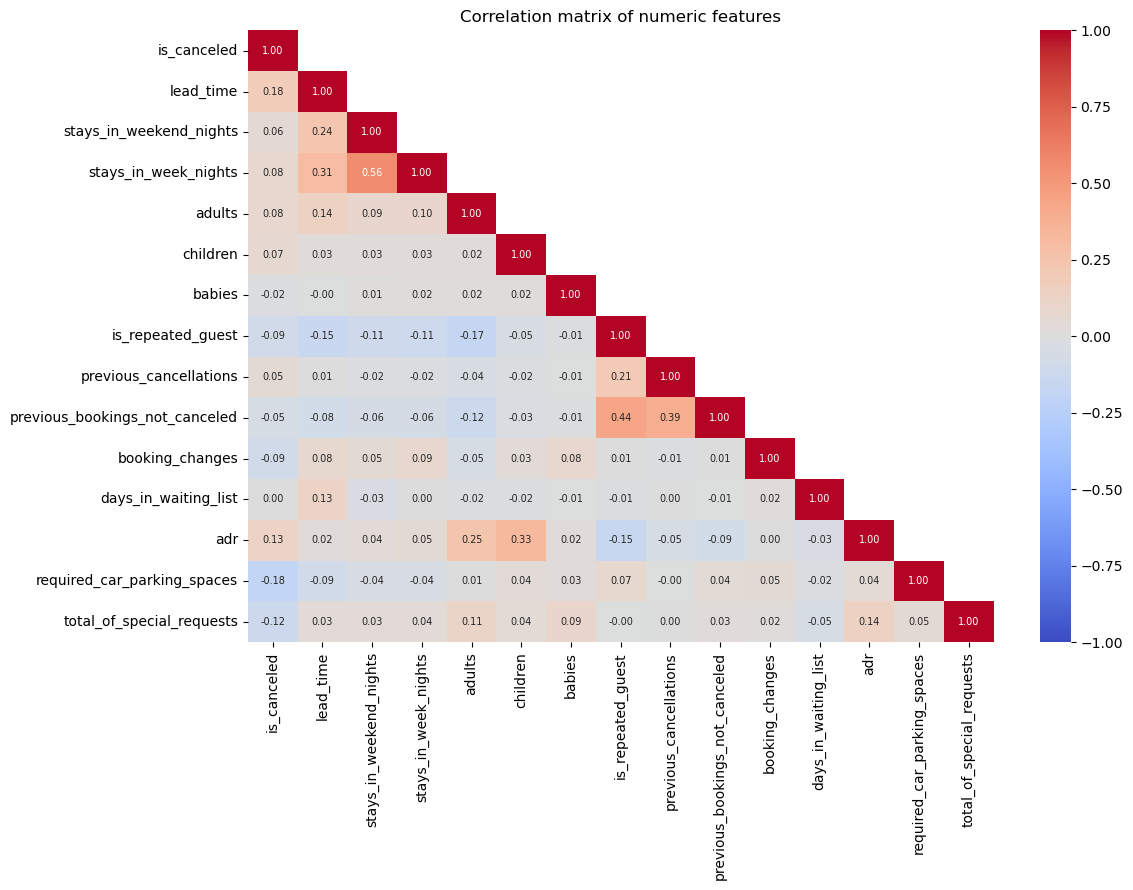

lead_time                         0.185
required_car_parking_spaces      -0.184
adr                               0.128
total_of_special_requests        -0.121
booking_changes                  -0.094
is_repeated_guest                -0.090
stays_in_week_nights              0.083
adults                            0.082
children                          0.067
stays_in_weekend_nights           0.060
previous_bookings_not_canceled   -0.052
previous_cancellations            0.051
babies                           -0.021
days_in_waiting_list              0.004
Name: is_canceled, dtype: float64


In [37]:
num_cols = ['is_canceled', 'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults',
            'children', 'babies', 'is_repeated_guest', 'previous_cancellations',
            'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr',
            'required_car_parking_spaces', 'total_of_special_requests']
corr = eda[num_cols].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot_kws={'size': 7})
plt.title('Correlation matrix of numeric features')
plt.tight_layout()
plt.show()
print(corr['is_canceled'].drop('is_canceled').sort_values(key=abs, ascending=False).round(3))

### EDA Takeaways
- **Duplicates:** 31,994 rows (27%) are exact duplicates. Removing them lowers the cancellation rate from 37.0% to 27.5%.
- **Class imbalance:** about 72.5% not canceled vs 27.5% canceled, so accuracy alone is misleading. We also report precision, recall, F1 and AUC.
- **Lead time** is the strongest numeric signal (r = 0.19). Bookings made months ahead cancel more often.
- **Deposit type:** "Non Refund" bookings cancel 95% of the time. This is counterintuitive, probably because non-refundable bookings are often bulk/group reservations made through travel agents and later dropped.
- **Commitment signals:** guests with special requests or parking requests rarely cancel (parking r = -0.18).
- **Market segment:** Online TA has the highest cancellation rate (35%); Corporate and Direct are the lowest.
- **Drift over time:** the cancellation rate rises in later periods, so our time-ordered test set (34.7% canceled) differs from the training set (25.7%).

In [5]:
df.shape

(87396, 32)

In [6]:
with pd.option_context('display.max_columns', None):
    display(df.head())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [7]:
df = df.drop(columns = ['reservation_status', 'reservation_status_date'])

In [8]:
for col in ['agent', 'company']:
    df[f'has_{col}'] = df[col].notna().astype(int)
    df[col] = df[col].apply(lambda v: 'none' if pd.isna(v) else str(int(v)))

In [9]:
with pd.option_context('display.max_columns', None):
    display(df.head())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_agent,has_company
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,none,none,0,Transient,0.0,0,0,0,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,none,none,0,Transient,0.0,0,0,0,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,none,none,0,Transient,75.0,0,0,0,0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304,none,0,Transient,75.0,0,0,1,0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240,none,0,Transient,98.0,0,1,1,0


In [10]:
df['children'] = df['children'].fillna(0).astype(int)
df['country'] = df['country'].fillna('unknown')

In [11]:
# no nulls after this point

In [12]:
cols = ['reserved_room_type', 'assigned_room_type']
df['got_room'] = np.where(df['reserved_room_type'] == df['assigned_room_type'], 1, 0)

In [13]:
df = df.drop(columns = cols)

In [14]:
import calendar
months = {m: i for i, m in enumerate(calendar.month_name) if m}

df['arrival_date'] = pd.to_datetime(dict(
    year=df['arrival_date_year'],
    month=df['arrival_date_month'].map(months),
    day=df['arrival_date_day_of_month'],
))

df['arrival_month'] = df['arrival_date'].dt.month
df['arrival_dow']   = df['arrival_date'].dt.dayofweek
df['is_weekend']    = (df['arrival_dow'] >= 5).astype(int)

df['month_sin'] = np.sin(2 * np.pi * df['arrival_month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['arrival_month'] / 12)

In [15]:
df = df.drop(columns=['arrival_date_year', 'arrival_date_month',
                      'arrival_date_week_number', 'arrival_date_day_of_month'])

In [16]:
df.shape

(87396, 33)

In [17]:
from sklearn.model_selection import train_test_split
df = df.sort_values('arrival_date').reset_index(drop=True)
X = df.drop(columns = 'is_canceled')
y = df['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state =42,
    shuffle = False)
X_train = X_train.drop(columns = 'arrival_date')
X_test = X_test.drop(columns = 'arrival_date')


In [18]:
from sklearn.preprocessing import OneHotEncoder

special_encoder = OneHotEncoder(handle_unknown='ignore', min_frequency=300, sparse_output=False)
special_encoder.set_output(transform='pandas')
special_cols = ['country', 'agent', 'company']

encoded_cols = special_encoder.fit_transform(X_train[special_cols])

X_train = pd.concat([X_train.drop(columns=special_cols), encoded_cols], axis=1)
encoded_cols = special_encoder.transform(X_test[special_cols])
X_test = pd.concat([X_test.drop(columns = special_cols), encoded_cols], axis=1)


In [19]:
# df['country'].value_counts().loc[lambda x: x > 100]
# df.head()
encoder = OneHotEncoder(handle_unknown = 'ignore', sparse_output=False)
encoder.set_output(transform='pandas')
cols = ['hotel', 'meal', 'distribution_channel', 'market_segment', 'deposit_type', 'customer_type', 'arrival_dow']

encoded_cols = encoder.fit_transform(X_train[cols])

X_train = pd.concat([X_train.drop(columns = cols), encoded_cols], axis = 1)
X_train = X_train.drop(columns = 'arrival_month')

encoded_cols = encoder.transform(X_test[cols])

X_test = pd.concat([X_test.drop(columns = cols), encoded_cols], axis = 1)
X_test = X_test.drop(columns = 'arrival_month')

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
numeric_cols = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights' ,'adults' ,
                'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled' , 'booking_changes',
                'days_in_waiting_list', 'adr' ,'total_of_special_requests' ,'required_car_parking_spaces']



In [21]:
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train_scaled[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test_scaled[numeric_cols])

In [22]:
X_train_scaled.head()


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,...,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,arrival_dow_0,arrival_dow_1,arrival_dow_2,arrival_dow_3,arrival_dow_4,arrival_dow_5,arrival_dow_6
0,3.421504,-0.953135,-1.242962,0.220548,-0.289226,-0.09634,0,-0.086325,-0.112462,3.802673,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.311529,2.910464,4.069247,0.220548,-0.289226,-0.09634,0,-0.086325,-0.112462,-0.374484,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.324120,0.978665,2.620463,0.220548,-0.289226,-0.09634,0,-0.086325,-0.112462,-0.374484,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-0.834252,-0.953135,-0.760034,-1.304056,-0.289226,-0.09634,0,-0.086325,2.360344,-0.374484,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,2.351269,-0.953135,-0.277106,0.220548,-0.289226,-0.09634,0,2.427421,-0.112462,-0.374484,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [23]:
X_train_scaled.shape

(69916, 105)

In [24]:
X_test_scaled.shape

(17480, 105)

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(random_state=42, max_iter = 300)
model.fit(X_train_scaled, y_train)

predictions = model.predict(X_test_scaled)
probabilities = model.predict_proba(X_test_scaled)
print(f"Accuracy: {accuracy_score(y_test, predictions):.2%}")

Accuracy: 76.08%


In [26]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components = 1, random_state = 42)
X_reduced_train = svd.fit_transform(X_train_scaled)
X_reduced_test = svd.transform(X_test_scaled)

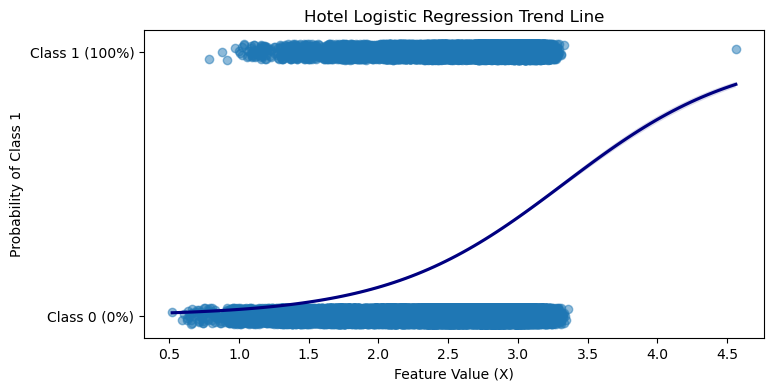

<Figure size 640x480 with 0 Axes>

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.figure(figsize=(8, 4))
# sns.regplot automatically handles the logistic curve fitting
sns.regplot(x=X_reduced_train, y=y_train, logistic=True, y_jitter=0.03, 
            scatter_kws={'alpha':0.5}, line_kws={'color':'navy'})

plt.yticks([0, 1], ['Class 0 (0%)', 'Class 1 (100%)'])
plt.xlabel('Feature Value (X)')
plt.ylabel('Probability of Class 1')
plt.title('Hotel Logistic Regression Trend Line')
plt.show()
plt.savefig('hotel.png')
